Acceder a los datos es bd y generar dos datasets hora y dia

In [16]:
from datetime import datetime
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

In [17]:
try:
    connection = sqlite3.connect("estacion_contaminantes_unam_mes060708.db")
except Exception as e:
    print('Error al conectar a db' + str(e))
try:
    df = pd.read_sql_query("SELECT fecha, pm2_5 FROM hpma where fecha between '2026-06-09 12:25' and '2026-08-11 12:01'", connection)
except Exception as e:
    print('Error al ejecutar query \t'+str(e))

In [18]:
datos_estacion_unam = df
datos_estacion_unam.head()

,fecha,pm2_5
0,2026-06-09 12:25,18.444444
1,2026-06-09 12:30,18.500000
2,2026-06-09 12:35,18.500000
3,2026-06-09 12:40,19.400000
4,2026-06-09 12:45,19.500000


asegura que fecha es datetime y elimina datos en 0 

In [19]:
if 'fecha' in datos_estacion_unam.columns:
    datos_estacion_unam['fecha'] = pd.to_datetime(datos_estacion_unam['fecha'], errors='coerce')
    datos_estacion_unam= datos_estacion_unam.set_index('fecha')
datos_estacion_unam.drop(datos_estacion_unam[datos_estacion_unam['pm2_5'] == 0].index, inplace=True)

resample por hora y relleno de datos faltantes si es solo uno

In [20]:
datos_hora = datos_estacion_unam.resample('h').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['pm2_5'] == 0) | (datos_copy['pm2_5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['pm2_5']
            val_posterior = datos_copy.iloc[i+1]['pm2_5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'pm2_5'] = valor_interpolado
    
datos_hora_interpolados = datos_copy
datos_hora_interpolados.head()

,fecha,pm2_5
0,2026-06-09 12:00:00,18.963492
1,2026-06-09 13:00:00,18.066667
2,2026-06-09 14:00:00,16.708333
3,2026-06-09 15:00:00,17.066667
4,2026-06-09 16:00:00,22.866667


dibuja grafica temporal de los datos 

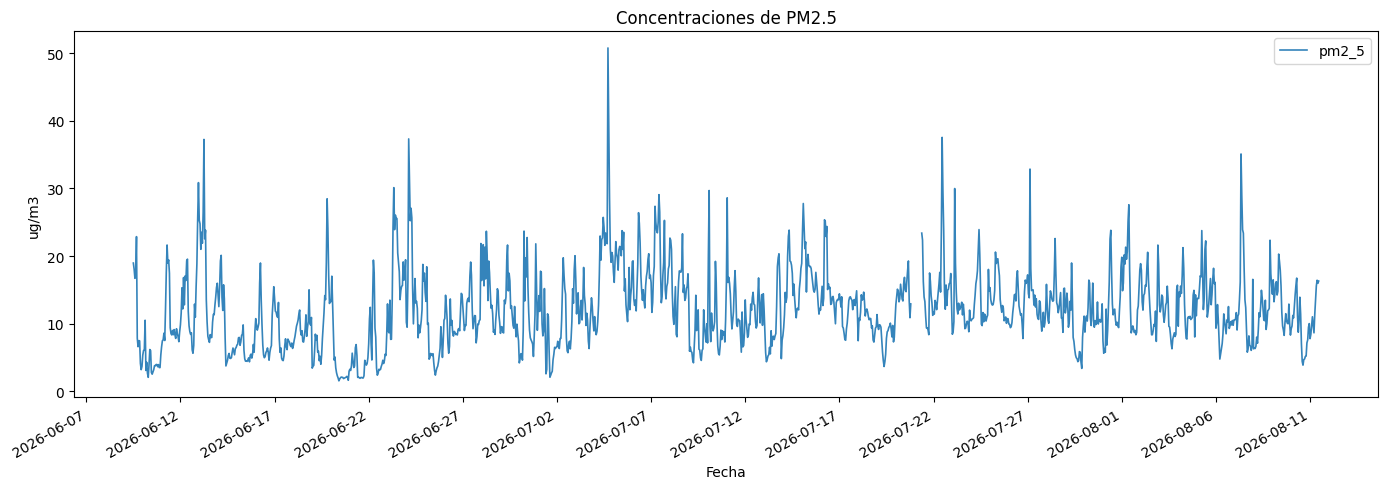

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_hora_interpolados['fecha'], datos_hora_interpolados["pm2_5"], label="pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

carga los datos de la estacion roua desde csv

In [22]:
def load_df_from_file(name):
    try:
        df = pd.read_csv(name)
        print("file loaded with columns : ")
        print(df.columns)
        return df
    except FileNotFoundError:
        print("File not found. Please ensure '"+name+"' is in the current directory.")
        return None

name = 'datos ruoa 06,07,08\\completo.csv'
datos_ruoa = load_df_from_file(name) 
datos_ruoa.head()

file loaded with columns : 
Index(['Time', 'O3', 'O3_flag', 'SO2', 'SO2_flag', 'NO2', 'NO2_flag', 'NO',
       'NO_flag', 'CO', 'CO_flag', 'PM10', 'PM10_flag', 'PM2.5', 'PM2.5_flag'],
      dtype='str')


,Time,O3,O3_flag,SO2,SO2_flag,NO2,NO2_flag,NO,NO_flag,CO,CO_flag,PM10,PM10_flag,PM2.5,PM2.5_flag
0,2026-06-01 00:00:00,39.72,OK,1.64,OK,0.61,OK,-0.23,BDL,0.20,OK,NaN,OS,17.55,OK
1,2026-06-01 01:00:00,36.77,OK,1.19,OK,0.75,OK,-0.23,BDL,0.20,OK,NaN,OS,8.99,OK
2,2026-06-01 02:00:00,29.57,OK,1.30,OK,1.02,OK,-0.24,BDL,0.21,OK,NaN,OS,12.45,OK
3,2026-06-01 03:00:00,22.86,OK,1.06,OK,1.40,OK,-0.23,BDL,0.22,OK,NaN,OS,11.49,OK
4,2026-06-01 04:00:00,22.22,OK,1.58,OK,1.85,OK,-0.21,BDL,0.20,OK,NaN,OS,12.99,OK


In [23]:
datos_ruoa_pm25 = datos_ruoa[['Time', 'PM2.5', 'PM2.5_flag']]
datos_ruoa_pm25.size

5058

filtro de acuerdo a la bandera

In [24]:
datos_ruoa_pm25 = datos_ruoa_pm25[datos_ruoa_pm25['PM2.5_flag'] == 'OK']
datos_ruoa_pm25 = datos_ruoa_pm25[(datos_ruoa_pm25['Time'] >= '2026-06-09 12:00') & (datos_ruoa_pm25['Time'] <= '2026-08-11 11:05')]
datos_ruoa_pm25.head()

,Time,PM2.5,PM2.5_flag
204,2026-06-09 12:00:00,14.97,OK
205,2026-06-09 13:00:00,17.18,OK
206,2026-06-09 14:00:00,25.75,OK
207,2026-06-09 15:00:00,11.07,OK
208,2026-06-09 16:00:00,26.50,OK


resampleado por hora y dia

In [25]:
datos_ruoa_pm25 = datos_ruoa_pm25[['Time', 'PM2.5']]
if 'Time' in datos_ruoa_pm25.columns:
    datos_ruoa_pm25['Time'] = pd.to_datetime(datos_ruoa_pm25['Time'], errors='coerce')
    datos_ruoa_pm25= datos_ruoa_pm25.set_index('Time')
datos_ruoa_pm25.drop(datos_ruoa_pm25[datos_ruoa_pm25['PM2.5'] == 0].index, inplace=True)

datos_hora = datos_ruoa_pm25.resample('h').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['PM2.5'] == 0) | (datos_copy['PM2.5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['PM2.5']
            val_posterior = datos_copy.iloc[i+1]['PM2.5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'PM2.5'] = valor_interpolado
    
datos_ruoa_interpolados = datos_copy
datos_ruoa_interpolados.head()

,Time,PM2.5
0,2026-06-09 12:00:00,14.97
1,2026-06-09 13:00:00,17.18
2,2026-06-09 14:00:00,25.75
3,2026-06-09 15:00:00,11.07
4,2026-06-09 16:00:00,26.50


dibuja grafica 

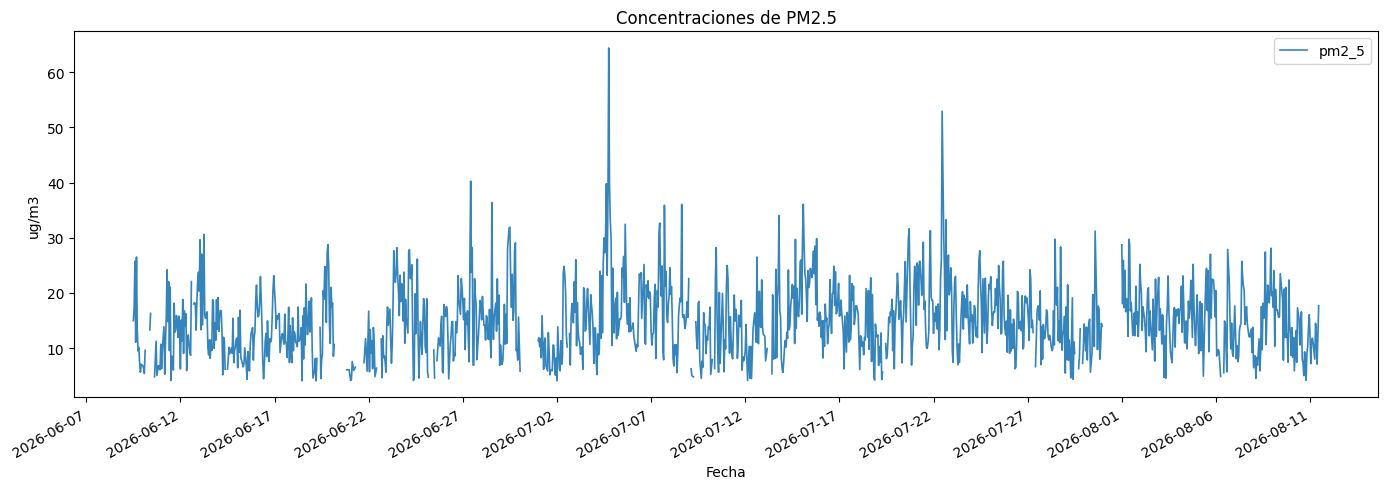

In [26]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_ruoa_interpolados['Time'], datos_ruoa_interpolados["PM2.5"], label="pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

dubuja grafica con las dos estaciones

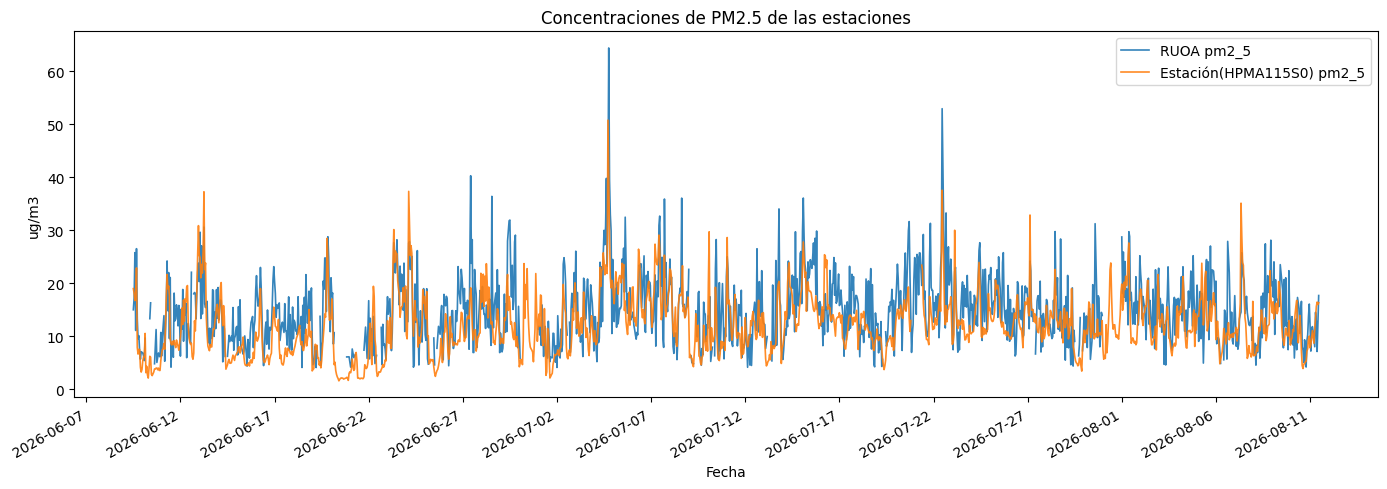

In [27]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_ruoa_interpolados['Time'], datos_ruoa_interpolados["PM2.5"], label="RUOA pm2_5", linewidth=1.2, alpha=0.9)
ax.plot(datos_hora_interpolados['fecha'], datos_hora_interpolados["pm2_5"], label="Estación(HPMA115S0) pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones de PM2.5 de las estaciones")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

unir ambos dataframes y generar grafico de dispersion con R2

In [28]:
datos_ruoa_interpolados.rename(columns={'Time': 'fecha', 'PM2.5': 'pm2_5'}, inplace=True)
datos_unidos_n = datos_hora_interpolados.merge(datos_ruoa_interpolados, how = 'inner', on ="fecha", suffixes=('_hpma115so', '_ruoa'))
datos_unidos = datos_unidos_n[datos_unidos_n['pm2_5_ruoa'].notna() & datos_unidos_n['pm2_5_hpma115so'].notna()]
datos_unidos.head()

,fecha,pm2_5_hpma115so,pm2_5_ruoa
0,2026-06-09 12:00:00,18.963492,14.97
1,2026-06-09 13:00:00,18.066667,17.18
2,2026-06-09 14:00:00,16.708333,25.75
3,2026-06-09 15:00:00,17.066667,11.07
4,2026-06-09 16:00:00,22.866667,26.50


grafico de dispersion

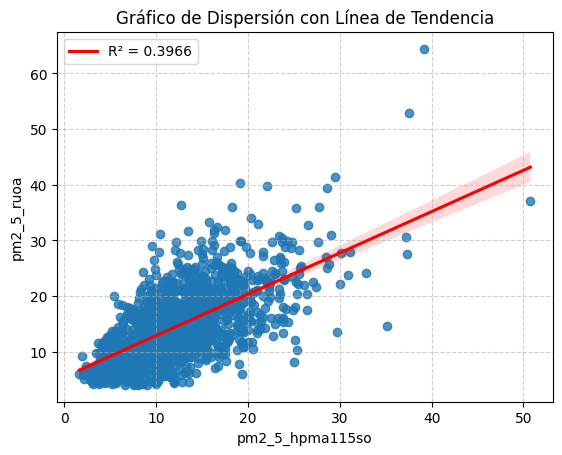

El coeficiente de determinación (R²) es: 0.3966


In [29]:

slope, intercept, r_value, p_value, std_err = stats.linregress(datos_unidos['pm2_5_hpma115so'], datos_unidos['pm2_5_ruoa'])

r_cuadrado = r_value ** 2

# 3. Crear el gráfico de dispersión con la línea de ajuste
# Se añade el valor de R² en la leyenda de la línea
sns.regplot(
    data=datos_unidos, 
    x='pm2_5_hpma115so', 
    y='pm2_5_ruoa', 
    line_kws={'label': f'R² = {r_cuadrado:.4f}', 'color': 'red'}
)

# Configuraciones adicionales del gráfico
plt.title('Gráfico de Dispersión con Línea de Tendencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar el gráfico
plt.show()

# 4. Imprimir el resultado en consola
print(f"El coeficiente de determinación (R²) es: {r_cuadrado:.4f}")

In [30]:
mae = mean_absolute_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_hpma115so'])
mse =  mean_squared_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_hpma115so'])
rmse = np.sqrt(mean_squared_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_hpma115so']))
mape = mean_absolute_percentage_error(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_hpma115so'])
r2 = r2_score(datos_unidos['pm2_5_ruoa'], datos_unidos['pm2_5_hpma115so'])

print("\t MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):")
print(f"MAE  (Error absoluto medio): {mae:.4f}")
print(f"MSE (Error cuadratico medio): {mse:.4f}")
print(f"MAPE : {mape:.1f}%")
print(f"RMSE (Raíz error cuadrático medio): {rmse:.4f}")
print(f"R²   (Coeficiente de determinación): {r2:.4f}")

	 MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):
MAE  (Error absoluto medio): 4.4452
MSE (Error cuadratico medio): 32.4940
MAPE : 0.3%
RMSE (Raíz error cuadrático medio): 5.7003
R²   (Coeficiente de determinación): 0.2268


promedios diarios

In [31]:
datos_dia = datos_estacion_unam.resample('D').mean().fillna(np.nan).reset_index()
datos_copy = datos_dia.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['pm2_5'] == 0) | (datos_copy['pm2_5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['pm2_5']
            val_posterior = datos_copy.iloc[i+1]['pm2_5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'pm2_5'] = valor_interpolado
    
datos_dia_interpolados = datos_copy
datos_dia_interpolados.head()

,fecha,pm2_5
0,2026-06-09,10.896003
1,2026-06-10,4.303125
2,2026-06-11,10.671181
3,2026-06-12,13.802431
4,2026-06-13,16.192708


In [32]:
if 'Time' in datos_ruoa_pm25.columns:
    datos_ruoa_pm25['Time'] = pd.to_datetime(datos_ruoa_pm25['Time'], errors='coerce')
    datos_ruoa_pm25= datos_ruoa_pm25.set_index('Time')
datos_ruoa_pm25.drop(datos_ruoa_pm25[datos_ruoa_pm25['PM2.5'] == 0].index, inplace=True)

datos_hora = datos_ruoa_pm25.resample('D').mean().fillna(np.nan).reset_index()
datos_copy = datos_hora.copy()
# Identificar donde hay valores 0 o NaN en pm2_5
mask_cero_null = (datos_copy['PM2.5'] == 0) | (datos_copy['PM2.5'].isnull())
    

# Procesar cada punto para encontrar valores aislados y aplicar interpolación
for i in range(len(datos_copy)):
    if mask_cero_null.iloc[i]:
        # Verificar si tiene valor anterior y posterior válidos (no 0/NaN)
        tiene_anterior = i > 0 and not mask_cero_null.iloc[i-1]
        tiene_posterior = i < len(datos_copy) - 1 and not mask_cero_null.iloc[i+1]
        
        # Si es aislado (rodeado por valores válidos), interpolar linealmente
        if tiene_anterior and tiene_posterior:
            val_anterior = datos_copy.iloc[i-1]['PM2.5']
            val_posterior = datos_copy.iloc[i+1]['PM2.5']
            # Interpolación lineal: promedio de los valores anterior y posterior
            valor_interpolado = (val_anterior + val_posterior) / 2
            datos_copy.at[i, 'PM2.5'] = valor_interpolado
    
datos_ruoa_dia = datos_copy
datos_ruoa_dia.head()

,Time,PM2.5
0,2026-06-09,13.473636
1,2026-06-10,8.356923
2,2026-06-11,12.829130
3,2026-06-12,14.495000
4,2026-06-13,16.010417


grafico temporal promedios diarios


In [33]:

datos_ruoa_dia.rename(columns={'Time': 'fecha', 'PM2.5': 'pm2_5'}, inplace=True)
datos_unidos_n = datos_dia_interpolados.merge(datos_ruoa_dia, how = 'inner', on ="fecha", suffixes=('_hpma115s0', '_ruoa'))
datos_unidos_dia = datos_unidos_n[datos_unidos_n['pm2_5_ruoa'].notna() & datos_unidos_n['pm2_5_hpma115s0'].notna()]
datos_unidos_dia.head()

,fecha,pm2_5_hpma115s0,pm2_5_ruoa
0,2026-06-09,10.896003,13.473636
1,2026-06-10,4.303125,8.356923
2,2026-06-11,10.671181,12.829130
3,2026-06-12,13.802431,14.495000
4,2026-06-13,16.192708,16.010417


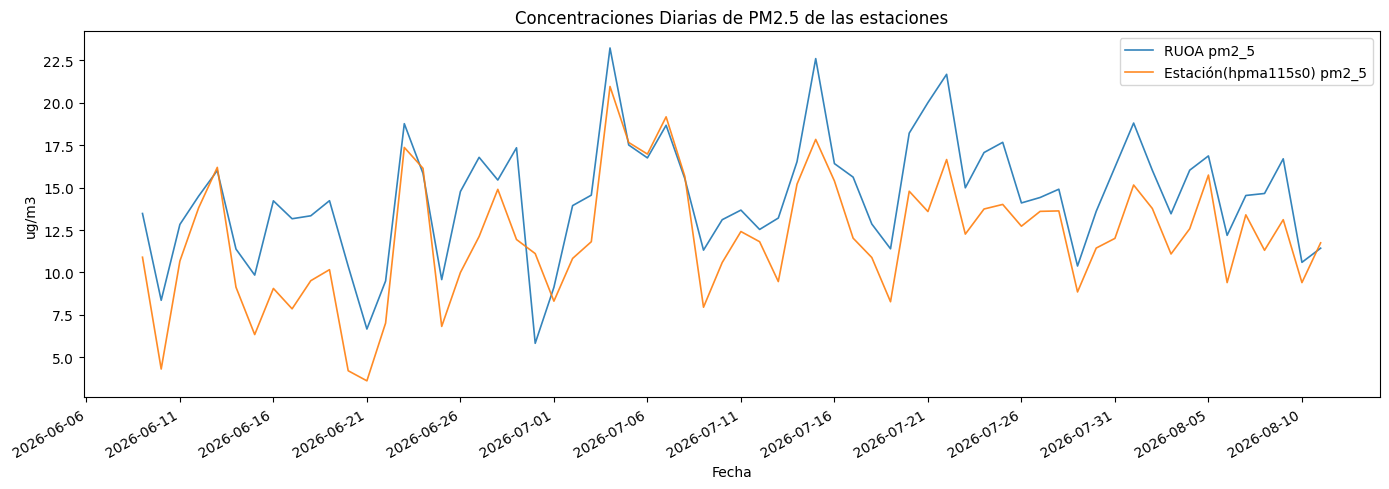

In [34]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos_unidos_dia['fecha'], datos_unidos_dia["pm2_5_ruoa"], label="RUOA pm2_5", linewidth=1.2, alpha=0.9)
ax.plot(datos_unidos_dia['fecha'], datos_unidos_dia["pm2_5_hpma115s0"], label="Estación(hpma115s0) pm2_5", linewidth=1.2, alpha=0.9)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5)) 
#formateador: cómo se ve el texto (YYYY-MM-DD)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
#ax.tick_params(axis='x', rotation=60)
fig.autofmt_xdate()
plt.title("Concentraciones Diarias de PM2.5 de las estaciones")
plt.xlabel('Fecha')
plt.ylabel('ug/m3')
plt.legend()
plt.tight_layout()
plt.show()

grafico de dispersion

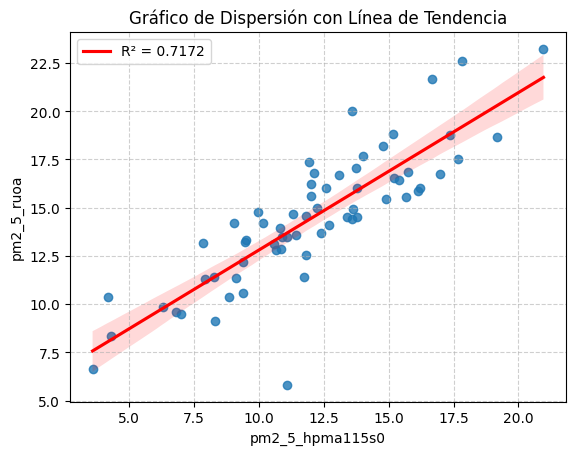

El coeficiente de determinación (R²) es: 0.7172


In [35]:
slope, intercept, r_value, p_value, std_err = stats.linregress(datos_unidos_dia['pm2_5_hpma115s0'], datos_unidos_dia['pm2_5_ruoa'])

r_cuadrado = r_value ** 2

# 3. Crear el gráfico de dispersión con la línea de ajuste
# Se añade el valor de R² en la leyenda de la línea
sns.regplot(
    data=datos_unidos_dia, 
    x='pm2_5_hpma115s0', 
    y='pm2_5_ruoa', 
    line_kws={'label': f'R² = {r_cuadrado:.4f}', 'color': 'red'}
)

# Configuraciones adicionales del gráfico
plt.title('Gráfico de Dispersión con Línea de Tendencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Mostrar el gráfico
plt.show()

# 4. Imprimir el resultado en consola
print(f"El coeficiente de determinación (R²) es: {r_cuadrado:.4f}")

In [37]:

mae = mean_absolute_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_hpma115s0'])
mse =  mean_squared_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_hpma115s0'])
rmse = np.sqrt(mean_squared_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_hpma115s0']))
mape = mean_absolute_percentage_error(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_hpma115s0'])
r2 = r2_score(datos_unidos_dia['pm2_5_ruoa'], datos_unidos_dia['pm2_5_hpma115s0'])

print("\t MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):")
print(f"MAE  (Error absoluto medio): {mae:.4f}")
print(f"MSE (Error cuadratico medio): {mse:.4f}")
print(f"MAPE : {mape:.1f}%")
print(f"RMSE (Raíz error cuadrático medio): {rmse:.4f}")
print(f"R²   (Coeficiente de determinación): {r2:.4f}")

	 MÉTRICAS DE EVALUACIÓN (Conjunto de prueba):
MAE  (Error absoluto medio): 2.6439
MSE (Error cuadratico medio): 9.6447
MAPE : 0.2%
RMSE (Raíz error cuadrático medio): 3.1056
R²   (Coeficiente de determinación): 0.1857
